In [18]:
BANDS_TO_USE = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12']
TARGET_SIZE = 120

# **Global ML**

Illegal mines: gather locations and timestamps, download multispectral images with ee

In [ ]:
save_dir_imgs = "./dataset/test/Global_ML/imgs/"
save_dir_masks = "./dataset/test/Global_ML/masks/"

In [45]:
import os
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.features import rasterize
import rioxarray
import fiona

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

import numpy as np

In [47]:
gpkg_path = './data/Global_ML/mining_area_data.gpkg'
print(f"layers:\n\t{fiona.listlayers(gpkg_path)}")

# Load the tiles table (contains the s2_tile_name)
gdf_tiles = gpd.read_file(gpkg_path, layer='tiles')
print(f"\ntiles table:\t{gdf_tiles.columns}")

# Load the validated polygons (or whichever polygon layer you intend to use)
gdf_polygons = gpd.read_file(gpkg_path, layer='test_polygons_validated') 
# Split the giant MULTIPOLYGON into individual mine polygons
gdf_polygons = gdf_polygons.explode(index_parts=False).reset_index(drop=True)
print(f"\npolygons table:\t{gdf_polygons.columns}")

# Merge them based on tile_id
gdf = gdf_polygons.merge(gdf_tiles[['tile_id', 's2_tile_id']], on='tile_id', how='left')

# apply projections
gdf_metric = gdf.to_crs(epsg=3857) 
gdf_buffered_metric = gdf_metric.copy()
gdf_buffered_metric['geometry'] = gdf_metric.geometry.centroid.buffer(600) # buffer of 600 meters around the centroid of each polygon
gdf_buffered_metric['geometry'] = gdf_buffered_metric['geometry'].envelope # cap the bounding box (makes it a perfect square)
gdf_buffered = gdf_buffered_metric.to_crs(epsg=4326)

print(f"\nMerged table:\t{gdf_buffered.columns}")

layers:
	['maus_polygons', 'tang_polygons', 'maus_bboxes', 'tang_bboxes', 'preferred_polygons', 'preferred_bboxes', 'tiles', 'test_polygons_validated']

tiles table:	Index(['tile_id', 's2_tile_id', 'source_dataset', 'preferred_dataset',
       'minetype1', 'minetype2', 'comment', 'timestamp', 'split', 'geometry'],
      dtype='object')

polygons table:	Index(['tile_id', 'geometry'], dtype='object')

Merged table:	Index(['tile_id', 'geometry', 's2_tile_id'], dtype='object')


In [ ]:
n_rois = len(gdf_buffered)

# download the mines multispectral images
for index, row in gdf_buffered.iterrows():
    minx, miny, maxx, maxy = row.geometry.bounds    # bounding box from the polygon geometry
    roi = ee.Geometry.Rectangle([minx, miny, maxx, maxy])
    
    s2_tile_id = row['s2_tile_id']
    print(f"\nProcessing ROI {index}/{n_rois-1} - Tile: {s2_tile_id}")

    try:
        # --------------- fetch the image
        parts = s2_tile_id.split('_')
        date_str = parts[2][:8]
        start_date = f"{date_str[:4]}-{date_str[4:6]}-{date_str[6:]}"
        end_date = (pd.to_datetime(start_date) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        mgrs_tile = parts[4][1:]
        # print(f"\nProcessing ROI {index} - Tile: {s2_tile_id}\n\tDate: {start_date}, MGRS: {mgrs_tile}")
        
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filter(ee.Filter.eq('MGRS_TILE', mgrs_tile)))
        
        if s2_collection.size().getInfo() == 0:
            print(f"Image {s2_tile_id} not found in Earth Engine.")
            continue

        s2_image = s2_collection.first().select(BANDS_TO_USE)
        
        # --------------- download the images (from the roi at the specified time interval) into the RAM
        ds = s2_image.wx.to_xarray(region=roi, scale=10, crs="EPSG:3857", progress=False)

        # --------------- convert data to numpy
        # stack bands
        data = np.stack([np.squeeze(ds[b].values) for b in BANDS_TO_USE], axis=0)    # (Channels, H, W)
        # Clean up any missing edge pixels and scale the Sentinel-2 L2A values
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- rasterize the mask
        ds = ds.rio.write_crs("EPSG:3857") # Explicitly register CRS to prevent rioxarray crashes
        transform = ds.rio.transform()
        out_shape = (img_array.shape[1], img_array.shape[2]) # (H, W)

        # Burn the original unbuffered polygon into the mask
        original_polygon = gdf_metric.loc[index].geometry
        mask_array = rasterize(
            [(original_polygon, 1)], # Label the polygon area as 1
            out_shape=out_shape,
            transform=transform,
            fill=0, # Background is 0
            dtype='uint8'
        )

        # --------------- force 120x120 shape to guarantee compatibility with ben-ge-8k
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]
        mask_array = mask_array[:TARGET_SIZE, :TARGET_SIZE]


        if img_array.max() == 0:
            print(f"Skipping ROI {index}: Image is empty (edge of swath).")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"Skipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        # label = "anomaly" if mask_array.sum() >= 5 else "normal"
        label = "anomaly"

        np.save(os.path.join(save_dir_imgs, f"mines_img_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"mines_img_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"Skipping ROI {index}, error: {e}")
        continue


Processing ROI 0/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 4 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 5/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 5 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 6/1196 - Tile: S2B_MSIL2A_20190527T144739_R139_T19LDD_20201006T190926
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing R

## Validating

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

def validate_mine_patch(index, img_dir, mask_dir, prefix):
    # File paths
    img_path = os.path.join(img_dir, f"{prefix}_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"{prefix}_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found.")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"Loaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    # Brighten the image slightly for better viewing (multiply by a factor, e.g., 2.5)
    rgb_bright = np.clip(rgb * 2.5, 0, 1)

    # Extract False Color Infrared (NIR, Red, Green: B8, B4, B3 -> Indices 7, 3, 2)
    # This makes vegetation appear bright red, and bare earth/mines appear cyan/grey
    fcc = img_array[[7, 3, 2], :, :].transpose(1, 2, 0)
    fcc_bright = np.clip(fcc * 2.5, 0, 1)

    # Setup the plot
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_bright)
    axes[0].set_title("True Color (RGB)")
    axes[0].axis("off")

    # 2. False Color
    axes[1].imshow(fcc_bright)
    axes[1].set_title("False Color (NIR-R-G)\nVegetation is Red, Dirt is Cyan")
    axes[1].axis("off")

    # 3. Mask Only
    axes[2].imshow(mask_array, cmap="gray")
    axes[2].set_title("Binary Mask")
    axes[2].axis("off")

    # 4. Mask Overlay on True Color
    axes[3].imshow(rgb_bright)
    # Overlay the mask using a red colormap and some transparency (alpha)
    # We mask out the '0' values so only the '1's (the mine) show up in red
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    axes[3].imshow(mask_overlay, cmap="autumn", alpha=0.5)
    
    # Alternatively, draw a contour line instead of a solid fill:
    # axes[3].contour(mask_array, levels=[0.5], colors=['red'], linewidths=1.5)

    axes[3].set_title("RGB with Mask Overlay")
    axes[3].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on a few of the files you just generated
prefix = "mines_img"
img_dir = "./dataset/test/Global_ML/imgs"
mask_dir = "./dataset/test/Global_ML/masks/"
for i in range(3):  # Assuming indices 0, 1, 2 exist based on your log
    validate_mine_patch(i, img_dir, mask_dir, prefix)

# **hls burn scars**
Burn scars: gather locations and timestamps, download multispectral images with ee

In [21]:
save_dir_imgs = "./dataset/test/hls_burn_scars/imgs"
save_dir_masks = "./dataset/test/hls_burn_scars/masks"

In [20]:
import os
import glob
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import rasterio
import rioxarray
import numpy as np

import ee
import wxee
from dotenv import load_dotenv
load_dotenv()
ee.Authenticate()
ee.Initialize(project=os.getenv("EAI_PROJECT_ID"))

In [22]:
# Locate all mask files in the dataset
mask_files = glob.glob('./data/hls_burn_scars/validation/*.mask.tif') 
num_files = len(mask_files)
print(f"{num_files} mask files")

for index, mask_path in enumerate(mask_files):
    # example filename: subsetted_512x512_HLS.S30.T10SEH.2018190.v1.4.mask.tif
    basename = os.path.basename(mask_path)
    parts = basename.split('.')
        
    print(f"\nProcessing ROI {index}/{num_files-1} - Tile: {parts[2]}")
    if parts[1] != 'S30':
        print(f"\tSkipping {index}: Not a Sentinel-2 (S30) patch.")
        continue

    try:
        date_str = parts[3]  # e.g., '2018190' (Year 2018, Julian Day 190)

        center_date = pd.to_datetime(date_str, format='%Y%j')
        start_date = (center_date - pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        end_date = (center_date + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
        
        # Open mask using rioxarray
        mask_da = rioxarray.open_rasterio(mask_path).squeeze()
        
        # --------------- Construct the ROI (1200m x 1200m)
        # HLS patches are 15km x 15km
        # ensure the 1200x1200m crop actually contains the burn scar by finding the center of the anomaly in the mask
        y_idx, x_idx = np.where(mask_da.values == 1)    # 1 = burn scar
        if len(y_idx) == 0:
            print(f"\tSkipping {index}: No burn scar found in this mask.")
            continue

        center_y, center_x = int(np.median(y_idx)), int(np.median(x_idx))
        lon, lat = mask_da.rio.transform() * (center_x + 0.5, center_y + 0.5)   # add 0.5 to get the exact center of the pixel
        
        pt = gpd.GeoSeries([Point(lon, lat)], crs=mask_da.rio.crs)
        # Buffer by 600m, make it a square
        roi_geom = pt.buffer(600).envelope.to_crs(epsg=4326).iloc[0]   # convert to Lat/Lon for Earth Engine
        minx, miny, maxx, maxy = roi_geom.bounds
        roi = ee.Geometry.Rectangle([minx, miny, maxx, maxy])

        # --------------- Fetch the image
        s2_collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                         .filterDate(start_date, end_date)
                         .filterBounds(roi))
        
        if s2_collection.size().getInfo() == 0:
            print(f"\tImage {basename} not found in Earth Engine.")
            continue

        # Mosaic to prevent partial tiles, and restore the time property
        s2_image = (s2_collection.mosaic()
                    .select(BANDS_TO_USE)
                    .set('system:time_start', ee.Date(start_date).millis()))
        
        # Download into RAM (Resampling to 10m Sentinel-2 resolution)
        # Request the download in the native UTM projection instead of EPSG:3857
        native_crs = mask_da.rio.crs.to_string()
        ds = s2_image.wx.to_xarray(region=roi, scale=10, crs=native_crs, progress=False)

        # --------------- Convert GEE Data to Numpy
        data = np.stack([np.squeeze(ds[b].values) for b in BANDS_TO_USE], axis=0)
        data_float = data.astype(np.float32) / 10000.0
        img_array = np.nan_to_num(data_float)

        # --------------- Resample the original HLS Mask to align with the GEE image
        ds = ds.rio.write_crs(native_crs) # use native CRS of the downloaded image
        
        # Warp, resize and crop the 30m HLS mask to perfectly match the 10m grid and bounding box of the downloaded Sentinel-2 array.
        matched_mask_da = mask_da.rio.reproject_match(ds, resampling=rasterio.enums.Resampling.nearest) # Nearest neighbor interpolation guarantees the mask remains strictly 0s and 1s
        mask_array = matched_mask_da.values.astype(np.uint8)

        # --------------- Force 120x120 shape for ben-ge-8k compatibility
        img_array = img_array[:, :TARGET_SIZE, :TARGET_SIZE]
        mask_array = mask_array[:TARGET_SIZE, :TARGET_SIZE]

        if img_array.max() == 0:
            print(f"\tSkipping ROI {index}: Image is empty (edge of swath).")
            continue
        if img_array.shape[1] < TARGET_SIZE or img_array.shape[2] < TARGET_SIZE:
            print(f"\tSkipping ROI {index}: Image is smaller than {TARGET_SIZE}x{TARGET_SIZE}.")
            continue

        # label = "anomaly" if mask_array.sum() >= 5 else "normal"
        label = "anomaly"

        np.save(os.path.join(save_dir_imgs, f"burn_patch_{index}_{label}.npy"), img_array)
        np.save(os.path.join(save_dir_masks, f"burn_patch_{index}_{label}_mask.npy"), mask_array)

        print(f"\tSaved ROI {index} - Image: {img_array.shape}, Mask: {mask_array.shape}")

    except Exception as e:
        print(f"Skipping {index}, error: {e}")
        continue

264 mask files

Processing ROI 0/263 - Tile: T16SEC
	Saved ROI 0 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 1/263 - Tile: T14SQG
	Saved ROI 1 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 2/263 - Tile: T11TMF
	Saved ROI 2 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 3/263 - Tile: T10TGL
	Saved ROI 3 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 4/263 - Tile: T17SNU
	Saved ROI 4 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 5/263 - Tile: T11TLL
	Saved ROI 5 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 6/263 - Tile: T17SLT
	Saved ROI 6 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 7/263 - Tile: T12TUN
	Saved ROI 7 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 8/263 - Tile: T16SGD
	Saved ROI 8 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 9/263 - Tile: T15TVN
	Saved ROI 9 - Image: (12, 120, 120), Mask: (120, 120)

Processing ROI 10/263 - Tile: T16REV
	Saved ROI 10 - Image: (12,

## Validating

Loaded ROI 261
Image shape: (12, 120, 120), Min: 0.0159, Max: 0.5952
Mask shape: (120, 120), Unique values: [0 1]


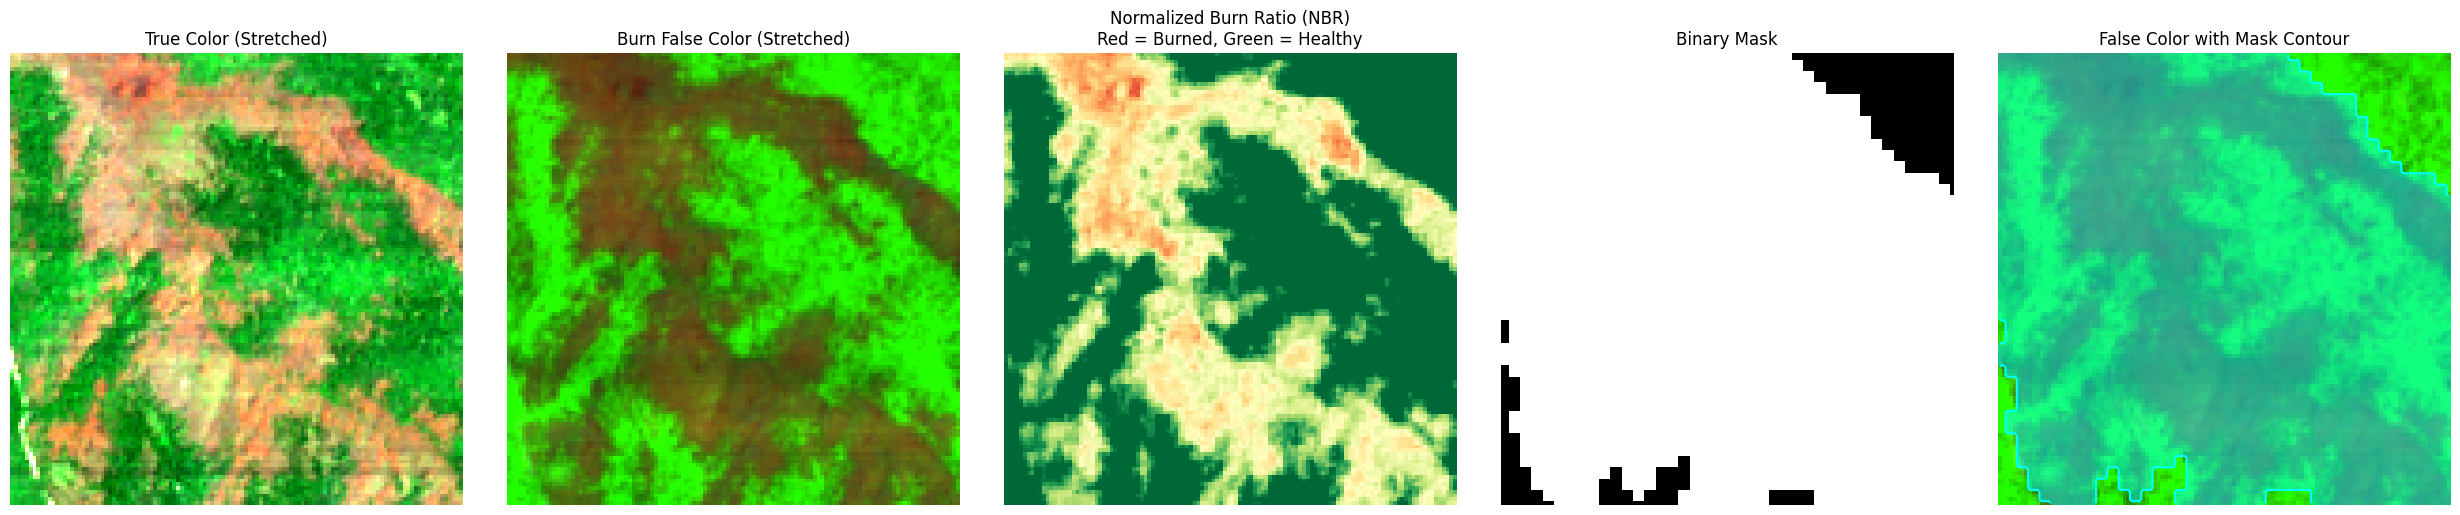

Loaded ROI 262
Image shape: (12, 120, 120), Min: 0.0250, Max: 0.3371
Mask shape: (120, 120), Unique values: [1]


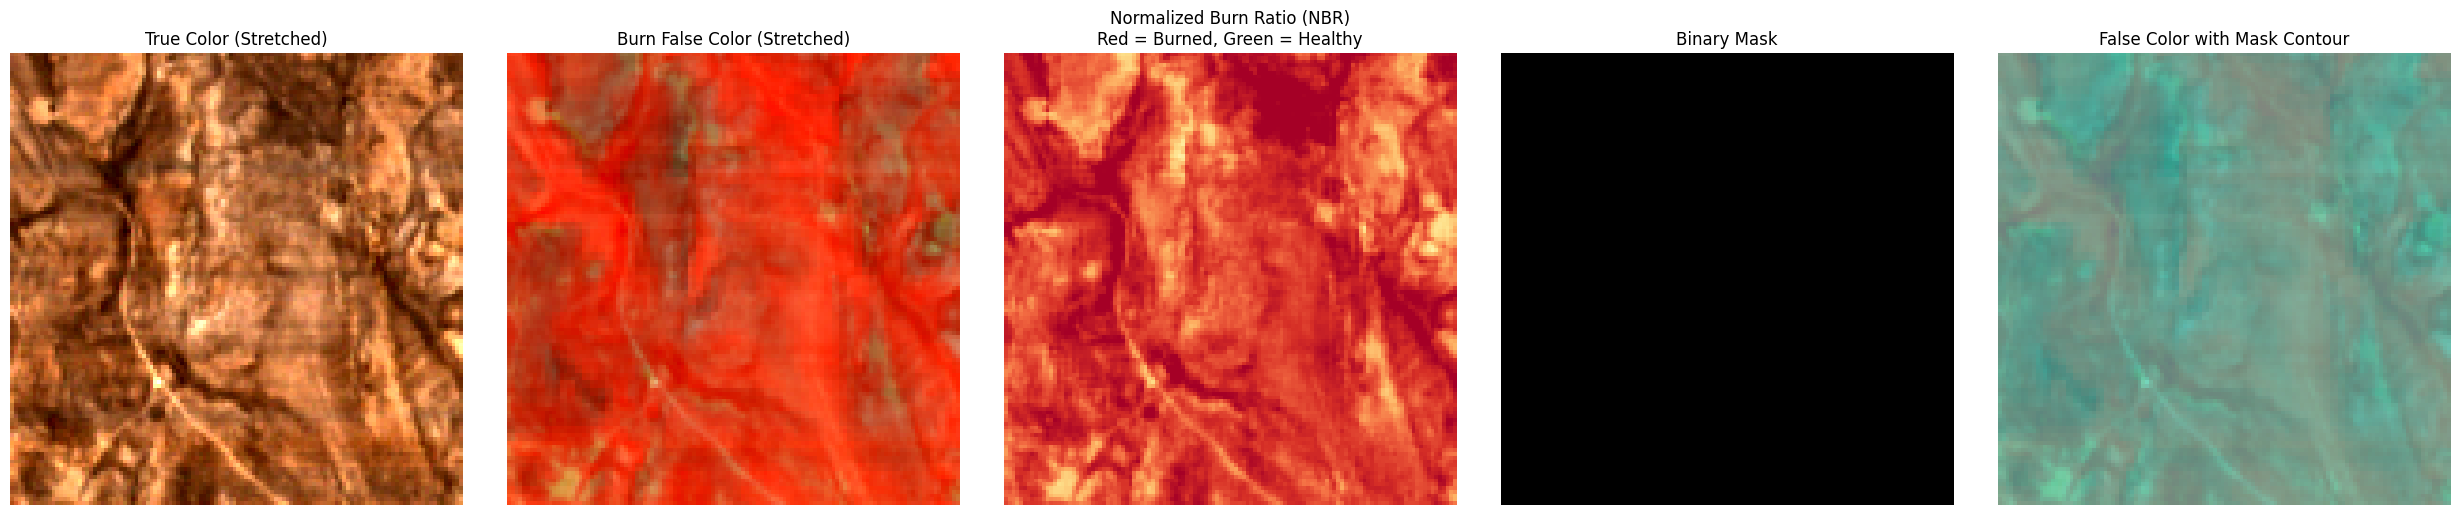

Loaded ROI 263
Image shape: (12, 120, 120), Min: 0.0199, Max: 0.4792
Mask shape: (120, 120), Unique values: [0 1]


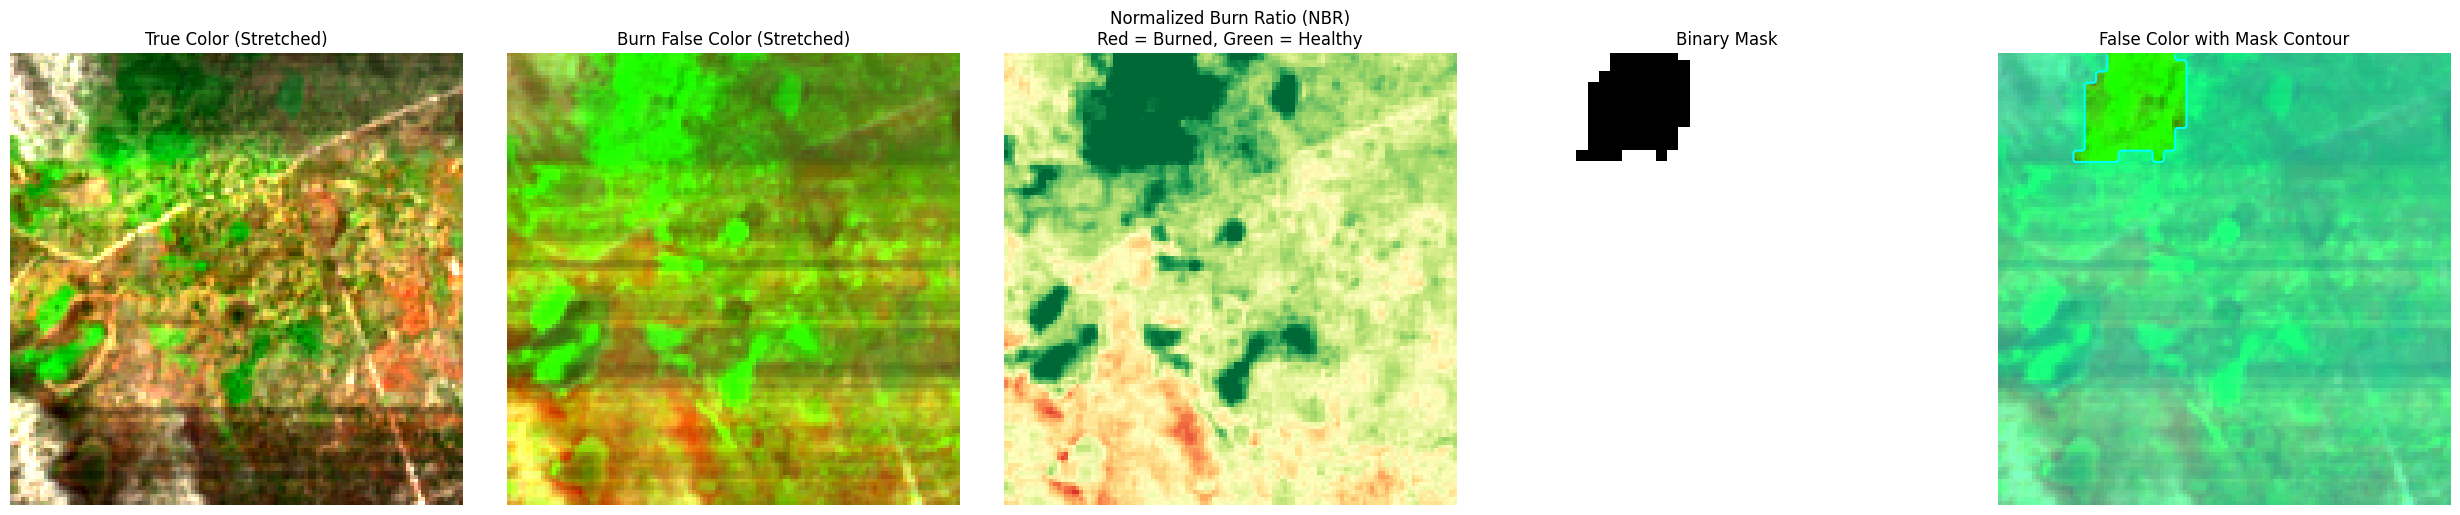

In [23]:
import os
import numpy as np
import matplotlib.pyplot as plt

# --- Helper function for robust contrast stretching ---
def robust_stretch(image_array):
    """Applies a 2nd-98th percentile stretch to each channel individually."""
    stretched = np.zeros_like(image_array)
    for i in range(image_array.shape[0]):
        band = image_array[i]
        p2, p98 = np.percentile(band, (2, 98))
        # Avoid division by zero if a band is completely flat
        if p98 - p2 == 0:
            stretched[i] = band
        else:
            stretched[i] = np.clip((band - p2) / (p98 - p2), 0, 1)
    return stretched

def validate_burn_patch(index, img_dir, mask_dir, prefix):
    # File paths
    img_path = os.path.join(img_dir, f"{prefix}_{index}_anomaly.npy")
    mask_path = os.path.join(mask_dir, f"{prefix}_{index}_anomaly_mask.npy")
    
    if not os.path.exists(img_path) or not os.path.exists(mask_path):
        print(f"Files for index {index} not found.")
        return

    # Load arrays
    img_array = np.load(img_path)   # Shape: (12, 120, 120)
    mask_array = np.load(mask_path) # Shape: (120, 120)
    
    print(f"Loaded ROI {index}")
    print(f"Image shape: {img_array.shape}, Min: {img_array.min():.4f}, Max: {img_array.max():.4f}")
    print(f"Mask shape: {mask_array.shape}, Unique values: {np.unique(mask_array)}")

    # Extract True Color (RGB: B4, B3, B2 -> Indices 3, 2, 1)
    rgb = img_array[[3, 2, 1], :, :].transpose(1, 2, 0)
    # # Brighten the image slightly for better viewing (multiply by a factor, e.g., 2.5)
    # rgb_bright = np.clip(rgb * 2.5, 0, 1)
    rgb_stretched = robust_stretch(rgb)

    # Extract Burn-Specific False Color (SWIR2, NIR, Red: B12, B8, B4 -> Indices 11, 7, 3)
    # Vegetation appears green, bare soil is tan/pink, and burn scars are stark dark red/brown.
    fcc = img_array[[11, 7, 3], :, :].transpose(1, 2, 0)
    # fcc_bright = np.clip(fcc * 2.5, 0, 1)
    fcc_stretched = robust_stretch(fcc)

    # Calculate Normalized Burn Ratio (NBR)
    # NBR = (NIR - SWIR2) / (NIR + SWIR2)
    nir = img_array[7, :, :]
    swir2 = img_array[11, :, :]
    nbr = (nir - swir2) / (nir + swir2 + 1e-8) # 1e-8 prevents division by zero

    # Setup the plot
    fig, axes = plt.subplots(1, 5, figsize=(25, 5))
    
    # 1. True Color
    axes[0].imshow(rgb_stretched)
    axes[0].set_title("True Color (Stretched)")
    axes[0].axis("off")

    # 2. Burn False Color
    axes[1].imshow(fcc_stretched)
    axes[1].set_title("Burn False Color (Stretched)")
    axes[1].axis("off")

    # Display NBR using a colormap where low values (burns) are visually distinct
    im = axes[2].imshow(nbr, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
    axes[2].set_title("Normalized Burn Ratio (NBR)\nRed = Burned, Green = Healthy")
    axes[2].axis("off")

    # 3. Mask Only
    axes[3].imshow(mask_array, cmap="gray")
    axes[3].set_title("Binary Mask")
    axes[3].axis("off")

    # 4. Mask Overlay on False Color
    axes[4].imshow(fcc_stretched)
    mask_overlay = np.ma.masked_where(mask_array == 0, mask_array)
    axes[4].imshow(mask_overlay, cmap="cool", alpha=0.5)
    
    # Draw a contour line instead of a solid fill:
    axes[4].contour(mask_array, levels=[0.5], colors=['cyan'], linewidths=1.5)

    axes[4].set_title("False Color with Mask Contour")
    axes[4].axis("off")

    plt.tight_layout()
    plt.show()

# Test it on a few of the files you just generated
prefix = "burn_patch"
img_dir = "./dataset/test/hls_burn_scars/imgs"
mask_dir = "./dataset/test/hls_burn_scars/masks/"
# for i in range(6):  # Assuming indices 0, 1, 2 exist based on your log
#     validate_burn_patch(i, img_dir, mask_dir, prefix)
validate_burn_patch(261, img_dir, mask_dir, prefix)
validate_burn_patch(262, img_dir, mask_dir, prefix)
validate_burn_patch(263, img_dir, mask_dir, prefix)